## Plot a Map to see potential geographical clustering

In [1]:
import sys
print(sys.executable)

c:\Users\tobia\anaconda3\envs\thesis_map\python.exe


In [2]:
# pip install geopandas

In [3]:
import os
import urllib.request
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

Communes in sample: 604 | Unmatched: 0 []
Far-right win communes plotted: 17
Far-right loss communes plotted: 587
Treated commune-elections: 26
Unique treated communes: 17
Communes that won in both cycles: ['02810', '30032', '57306', '62427', '83042', '83061', '84029', '84087', '84092']
Treated communes on the map: 17
Treated communes missing from the map: []


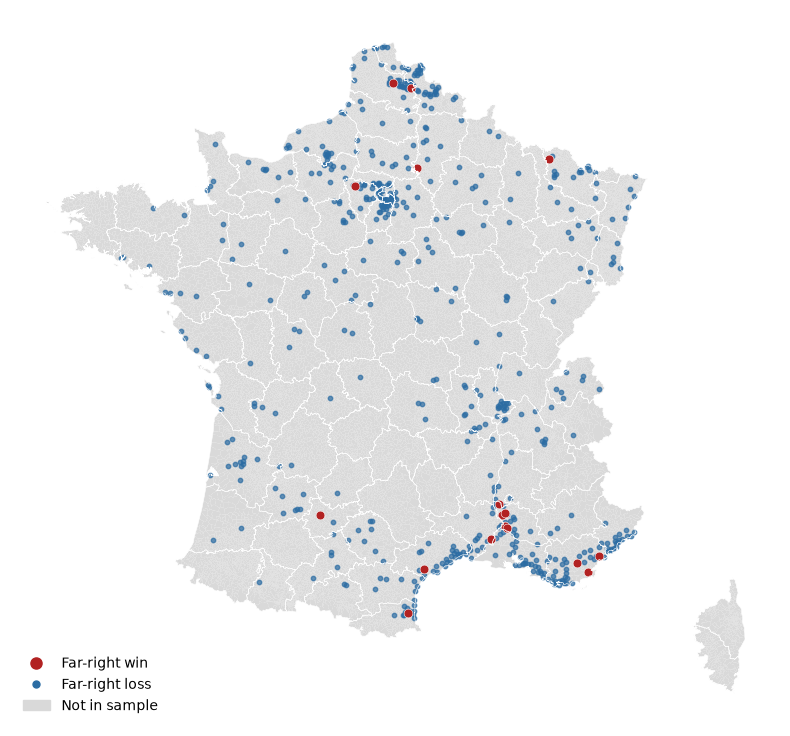

In [4]:
# 1. Download the boundaries once (source: gregoiredavid/france-geojson, 2018 geography)
base_url = 'https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/'
for file in ['communes.geojson', 'departements.geojson']:
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

communes = gpd.read_file('communes.geojson').to_crs(2154)        # 2154 = French projected CRS
departments = gpd.read_file('departements.geojson').to_crs(2154)
communes['code'] = communes['code'].astype(str).str.zfill(5)

# 2. Load the RDD sample and keep the two estimation cycles
df_rdd = pd.read_csv('df_rdd_clean.csv', dtype={'code_commune': str})
df_rdd['code_commune'] = df_rdd['code_commune'].str.zfill(5)
df_rdd = df_rdd[df_rdd['election_year'].isin([2014, 2020])]

# 3. One row per commune: 1 if the far right won in either cycle, otherwise 0
status = df_rdd.groupby('code_commune', as_index=False)['treat'].max()

# 4. Check for codes that are missing from the 2018 map
unmatched = sorted(set(status['code_commune']) - set(communes['code']))
print('Communes in sample:', len(status), '| Unmatched:', len(unmatched), unmatched[:20])

# 5. Merge, keeping every commune on the map
map_df = communes.merge(status, left_on='code', right_on='code_commune', how='left')
points = map_df[map_df['treat'].notna()].copy()
points['geometry'] = points.centroid                             # a point for each sample commune

print('Far-right win communes plotted:', (points['treat'] == 1).sum())
print('Far-right loss communes plotted:', (points['treat'] == 0).sum())

# 6. Plot
fig, ax = plt.subplots(figsize=(8, 8))
map_df.plot(ax=ax, color='#d9d9d9', edgecolor='none', rasterized=True)   # all communes
departments.boundary.plot(ax=ax, color='white', linewidth=0.4)
points[points['treat'] == 0].plot(ax=ax, color='#2b6ca3', markersize=10, alpha=0.7)
points[points['treat'] == 1].plot(ax=ax, color='firebrick', markersize=40,
                                  edgecolor='white', linewidth=0.4)

ax.legend(handles=[
    Line2D([0], [0], marker='o', ls='', color='firebrick', markersize=8, label='Far-right win'),
    Line2D([0], [0], marker='o', ls='', color='#2b6ca3', markersize=5, label='Far-right loss'),
    Patch(color='#d9d9d9', label='Not in sample'),
], frameon=False, loc='lower left')
ax.set_axis_off()

treated = df_rdd[df_rdd['treat'] == 1]
treated_communes = set(treated['code_commune'])
map_codes = set(communes['code'])

print('Treated commune-elections:', len(treated))
print('Unique treated communes:', len(treated_communes))

wins = treated.groupby('code_commune')['election_year'].nunique()
print('Communes that won in both cycles:', sorted(wins[wins == 2].index))

print('Treated communes on the map:', len(treated_communes & map_codes))
print('Treated communes missing from the map:', sorted(treated_communes - map_codes))


plt.tight_layout()
plt.savefig('map_sample.pdf', bbox_inches='tight', dpi=300)
plt.show()